# Topological signatures of human activity

This notebook follows one sensor window all the way from a sampled signal to a topological feature vector and then asks whether that vector distinguishes human activities for people the model has not seen.

The central construction is

$$
\text{sensor window}
\longrightarrow
\text{delay cloud}
\longrightarrow
\text{persistence diagram}
\longrightarrow
\text{stable rank or circular coordinate}
\longrightarrow
\text{activity comparison}.
$$

The point of the notebook is not merely to display classification scores. It explains what mathematical object is created at each arrow, why that object is used, and what information is gained or discarded.

The main conclusion is deliberately limited: delay-cloud topology contains reproducible information about motion geometry and temporal adjacency, but ordinary signal features classify these activities substantially better. The topological representation is therefore most valuable as an interpretable description of motion rather than as the strongest predictor.


## Roadmap

The analysis has six conceptual steps.

1. **Choose the datum.** One datum is a 2.56-second window containing simultaneous acceleration and angular-velocity samples.
2. **Reconstruct local motion histories.** Delay coordinates replace each instantaneous sample by a short sequence of measurements.
3. **Measure the geometry at every scale.** A Vietoris--Rips filtration connects nearby delay vectors as the distance threshold grows.
4. **Record persistent structure.** Persistent homology tracks connected components in $H_0$ and loops in $H_1$.
5. **Vectorize the barcode.** Stable ranks turn a variable-sized persistence diagram into a fixed-length function sampled on a common grid. A second branch converts the longest persistent cocycle into a circular phase coordinate.
6. **Compare activities without mixing people.** The classifier is evaluated by subject so that success means transfer to new people, not recognition of a person's characteristic movement.

This notebook is the single analysis entry point. Each experimental section calls one named function from `experiments.py`; those functions contain caching and repeated numerical machinery, while every scientific choice and every call appear here in the order discussed. Set `RECOMPUTE=True` to refit every model and refresh every result. With the default `False`, existing verified results and feature caches are reused.


In [1]:
from pathlib import Path

import numpy as np

from data_loader import ACTIVITY_NAMES, check_data, load_inertial_data

root = Path.cwd()
RECOMPUTE = False


## 1. The observation: one short movement window

The UCI HAR experiment records body acceleration and angular velocity at 50 Hz. One observation $w$ contains 128 simultaneous samples, so it covers

$$
\frac{128}{50}=2.56\text{ seconds}.
$$

At sample index $i$ the two triaxial measurements are

$$
a_w(i),\omega_w(i)\in\mathbb{R}^3,
\qquad i=0,\ldots,127.
$$

The arrays use the same first index:

$$
\texttt{acceleration[w]}
\longleftrightarrow
\texttt{gyroscope[w]}
\longleftrightarrow
\texttt{labels[w]}
\longleftrightarrow
\texttt{subjects[w]}.
$$

Thus one row is not one time sample. It is one complete 2.56-second observation from one person performing one of six activities.


In [2]:
train_sensors, labels, subjects = load_inertial_data("train")
test_sensors, test_labels, test_subjects = load_inertial_data("test")

acceleration = train_sensors["body_acc"]
gyroscope = train_sensors["body_gyro"]

check_data(acceleration, labels, subjects)
check_data(gyroscope, labels, subjects)
print("Test windows:", len(test_labels))
print("Training subjects:", len(np.unique(subjects)))
print("Test subjects:", len(np.unique(test_subjects)))
print("Disjoint subject sets:", set(subjects).isdisjoint(test_subjects))


Signals: (7352, 128, 3)
Labels: (7352,)
Subjects: (7352,)
Number of subjects: 21
Walking: 1226
Walking upstairs: 1073
Walking downstairs: 986
Sitting: 1286
Standing: 1374
Laying: 1407
Signals: (7352, 128, 3)
Labels: (7352,)
Subjects: (7352,)
Number of subjects: 21
Walking: 1226
Walking upstairs: 1073
Walking downstairs: 986
Sitting: 1286
Standing: 1374
Laying: 1407
Test windows: 2947
Training subjects: 21
Test subjects: 9
Disjoint subject sets: True


The two sensor tensors have shape `(windows, 128, 3)`. The first coordinate selects an observation, the second moves through time, and the third selects the $x$, $y$, or $z$ axis.

The subject split matters later because consecutive windows overlap by 50%. Randomly splitting windows would allow nearly adjacent pieces of the same person's motion into training and validation. Grouping by subject instead asks the harder and more meaningful question: does the representation transfer to a person who contributed no training window?


In [3]:
w = 0
acceleration_window = acceleration[w]
gyroscope_window = gyroscope[w]

print("Activity:", ACTIVITY_NAMES[labels[w]])
print("Subject:", subjects[w])
print("Acceleration shape:", acceleration_window.shape)
print("Gyroscope shape:", gyroscope_window.shape)


Activity: Standing
Subject: 1
Acceleration shape: (128, 3)
Gyroscope shape: (128, 3)


### Reading one window as a signal

The following plot keeps time on the horizontal axis and shows the three acceleration coordinates separately. Periodic motion should appear as repeated oscillation; static activities should fluctuate around a more stable configuration.

This is the original signal representation. The topological construction will deliberately replace this ordered curve by a point cloud whose points encode short temporal histories.


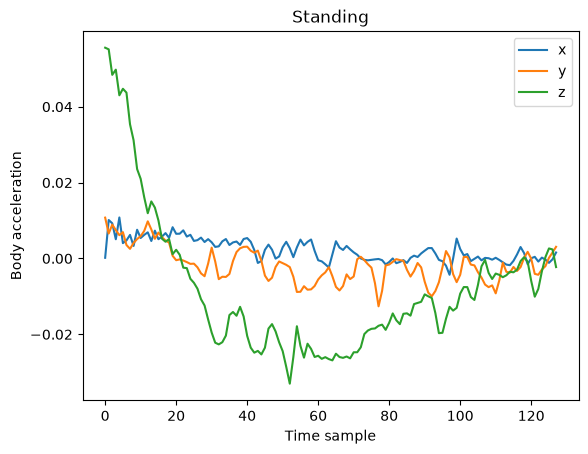

In [4]:
from plotting import plot_time_series

plot_time_series(acceleration_window, title=ACTIVITY_NAMES[labels[w]])


### The raw three-dimensional trajectory

If the three acceleration axes are treated as spatial coordinates, a window traces a path in $\mathbb{R}^3$. The panels below use one window from each activity for the same person and share the same coordinate limits.

Walking activities often trace larger repeated paths, while sitting, standing, and lying remain more compact. This is useful intuition, but it is not yet the object used for persistence: a raw point $a_w(i)$ contains only the measurement at time $i$ and forgets what happened immediately before and after it.


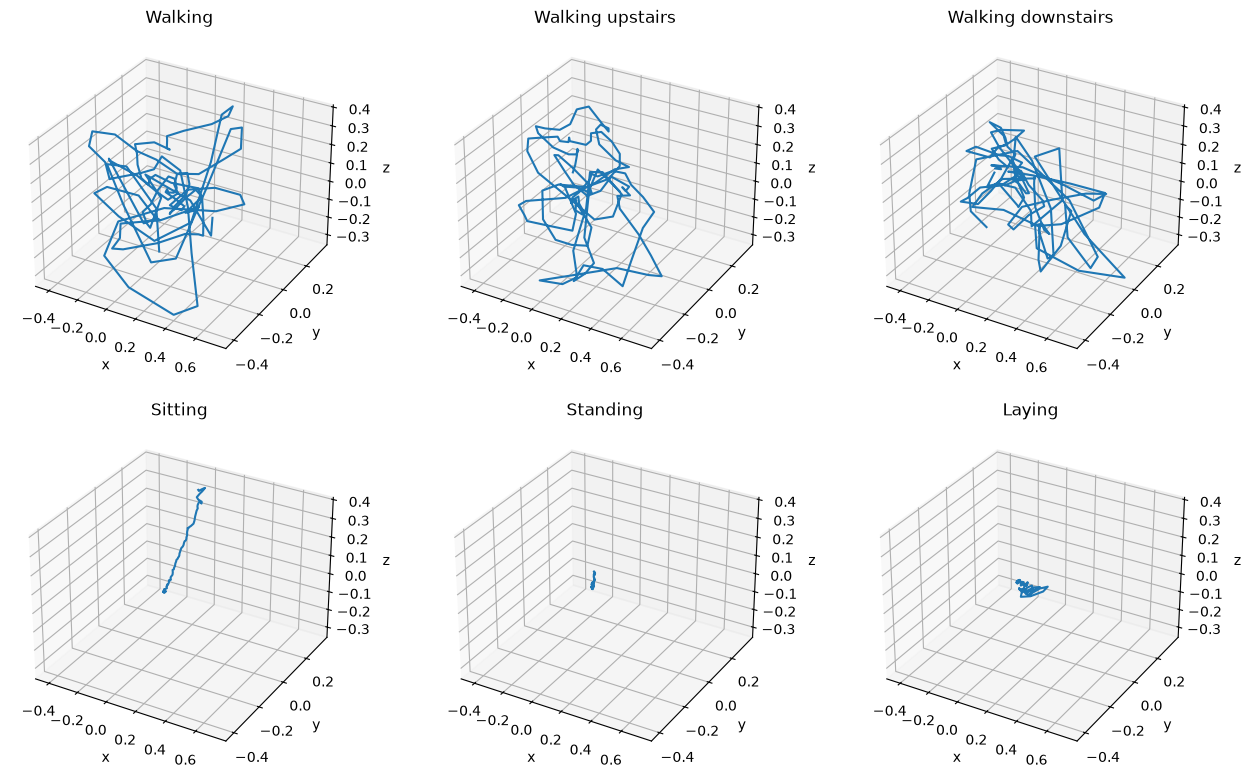

In [5]:
from plotting import plot_activity_trajectories

plot_activity_trajectories(acceleration, labels, subjects, subject=1)


## 2. Delay coordinates: turning samples into motion fragments

An instantaneous acceleration vector may occur during several different movements. Delay coordinates attach nearby measurements to it so that one point represents a short motion history.

For embedding dimension $m$ and lag $\ell$, define

$$
\Phi_{m,\ell}(i)
=
\bigl(
a_w(i),
a_w(i+\ell),
\ldots,
a_w(i+(m-1)\ell)
\bigr).
$$

Because every $a_w(i)$ has three coordinates, $\Phi_{m,\ell}(i)$ lies in $\mathbb{R}^{3m}$. The largest valid starting index is $127-(m-1)\ell$, so the delay cloud has

$$
n_{\text{points}}=128-(m-1)\ell
$$

points. For the chosen values $m=3$ and $\ell=15$, each point is

$$
\Phi_{3,15}(i)=\bigl(a_w(i),a_w(i+15),a_w(i+30)\bigr)\in\mathbb{R}^9,
$$

and the cloud has $128-30=98$ points. At 50 Hz, the first and last measurements in one delay vector are 0.60 seconds apart.

This is a Takens-type representation, not a claim that the full hypotheses of Takens' theorem hold for these short noisy windows. Its practical purpose here is precise: geometry in the cloud should depend on local temporal adjacency, whereas the unordered instantaneous cloud cannot depend on sample order.


### Choosing the lag

If $\ell$ is too small, the three blocks in a delay vector are nearly duplicates. If it is too large, they may describe unrelated parts of the window. For a centered scalar signal $x_i$, the lag-$k$ autocorrelation is

$$
\rho(k)=\frac{\sum_i x_i x_{i+k}}{\sum_i x_i^2}.
$$

The plotted curve averages this quantity over all training windows and acceleration axes. Its first non-positive value provides a simple scale at which linear similarity to the present measurement has decayed.

The lag is chosen from training data only and then held fixed. The embedding dimension $m=3$ is small enough to retain 98 points per window while allowing the cloud to encode a three-stage motion fragment.


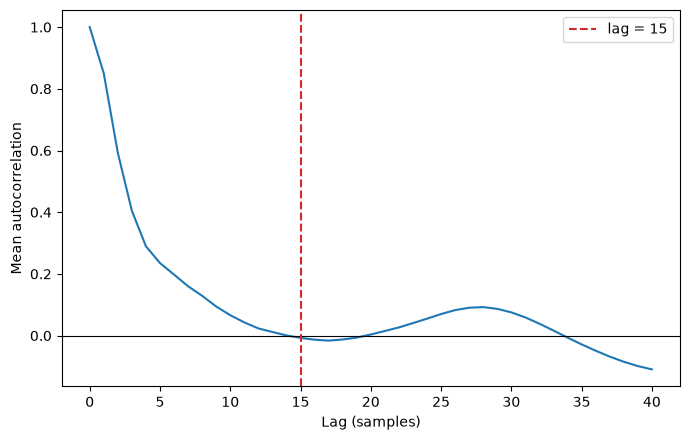

Chosen lag: 15 samples
Lag in seconds: 0.3
History span in seconds: 0.6


In [6]:
from embedding import first_nonpositive_lag, mean_autocorrelation
from plotting import plot_mean_autocorrelation

autocorrelation = mean_autocorrelation(acceleration, max_lag=40)
lag = first_nonpositive_lag(autocorrelation)
m = 3

plot_mean_autocorrelation(autocorrelation, lag)
print("Chosen lag:", lag, "samples")
print("Lag in seconds:", lag / 50)
print("History span in seconds:", (m - 1) * lag / 50)


The first zero crossing occurs at $\ell=15$, corresponding to 0.30 seconds. This number should not be interpreted as a uniquely correct physical period. It is a defensible coordinate scale whose sensitivity is checked later by trying shorter and longer lags.


In [7]:
from embedding import delay_embedding, joint_delay_embedding

acceleration_cloud = delay_embedding(acceleration_window, m, lag)
gyroscope_cloud = delay_embedding(gyroscope_window, m, lag)
joint_cloud = joint_delay_embedding(acceleration_window, gyroscope_window, m, lag)

print("Acceleration cloud:", acceleration_cloud.shape)
print("Gyroscope cloud:", gyroscope_cloud.shape)
print("Joint cloud:", joint_cloud.shape)


Acceleration cloud: (98, 9)
Gyroscope cloud: (98, 9)
Joint cloud: (98, 18)


The separate sensor clouds have shape $98\times9$. The synchronized joint cloud places the acceleration and gyroscope delay vectors with the same starting index beside one another, producing 98 points in $\mathbb{R}^{18}$.

The next cell exposes exactly how the first acceleration delay point is assembled. This is the essential transition from a time series to a geometric dataset.


In [8]:
expected_first_delay_point = np.concatenate(
    [acceleration_window[0], acceleration_window[15], acceleration_window[30]]
)

print("First delay point equals samples 0, 15, and 30:",
      np.allclose(acceleration_cloud[0], expected_first_delay_point))
print("First delay point:")
print(np.round(acceleration_cloud[0], 4))


First delay point equals samples 0, 15, and 30: True
First delay point:
[ 0.0002  0.0108  0.0556  0.0051  0.0068  0.01    0.0043  0.0029 -0.0195]


### Centering and scale normalization

Persistence depends on pairwise distances. Multiplying every acceleration value by a constant would therefore multiply every birth and death scale even if the shape of the motion were unchanged.

For a cloud $X=\{x_1,\ldots,x_n\}$, define its center and RMS radius by

$$
\bar x=\frac1n\sum_{i=1}^n x_i,
\qquad
r(X)=\sqrt{\frac1n\sum_{i=1}^n\lVert x_i-\bar x\rVert_2^2}.
$$

The primary representation uses

$$
\widetilde x_i=\frac{x_i-\bar x}{r(X)}.
$$

Every normalized cloud is centered and has RMS radius one. This makes persistence describe relative shape rather than absolute amplitude. The removed acceleration and gyroscope radii are saved separately so that a later comparison can measure the information lost by normalization.


In [9]:
from topology import make_point_cloud

raw_cloud, acceleration_scale = make_point_cloud(
    acceleration_window, m, lag, normalize=False
)
normalized_cloud, _ = make_point_cloud(
    acceleration_window, m, lag, normalize=True
)

def rms_radius(cloud):
    centered = cloud - cloud.mean(axis=0)
    return np.sqrt(np.mean(np.sum(centered**2, axis=1)))

print("Saved RMS radius:", round(acceleration_scale, 6))
print("Measured raw RMS radius:", round(rms_radius(raw_cloud), 6))
print("Normalized cloud mean norm:", round(np.linalg.norm(normalized_cloud.mean(axis=0)), 12))
print("Normalized RMS radius:", round(rms_radius(normalized_cloud), 6))


Saved RMS radius: 0.02579
Measured raw RMS radius: 0.02579
Normalized cloud mean norm: 0.0
Normalized RMS radius: 1.0


## 3. Vietoris--Rips persistence: geometry across scales

The delay cloud is finite, so it has no continuous curve or surface built into it. A Vietoris--Rips filtration supplies a family of simplicial complexes indexed by a distance threshold $\varepsilon$:

- every delay vector is a vertex;
- two vertices share an edge when their distance is at most $\varepsilon$;
- a set of vertices forms a simplex when every pair in the set is connected.

As $\varepsilon$ increases, edges and higher-dimensional simplices are added but never removed:

$$
\operatorname{VR}_{\varepsilon_1}(X)
\subseteq
\operatorname{VR}_{\varepsilon_2}(X),
\qquad \varepsilon_1\leq\varepsilon_2.
$$

Persistent homology records when topological classes appear and disappear through this nested family.

- $H_0$ tracks connected components. Initially every point is separate; components die when clusters merge.
- $H_1$ tracks one-dimensional loops. A loop is born when edges close a cycle and dies when triangles fill it.

A persistence-diagram point $(b,d)$ records birth $b$, death $d$, and lifetime $d-b$. A point far above the diagonal has a long lifetime and survives a wide range of distance thresholds.

An $H_1$ class is a loop in the reconstructed delay cloud. It is not automatically a literal circular path of the human body.


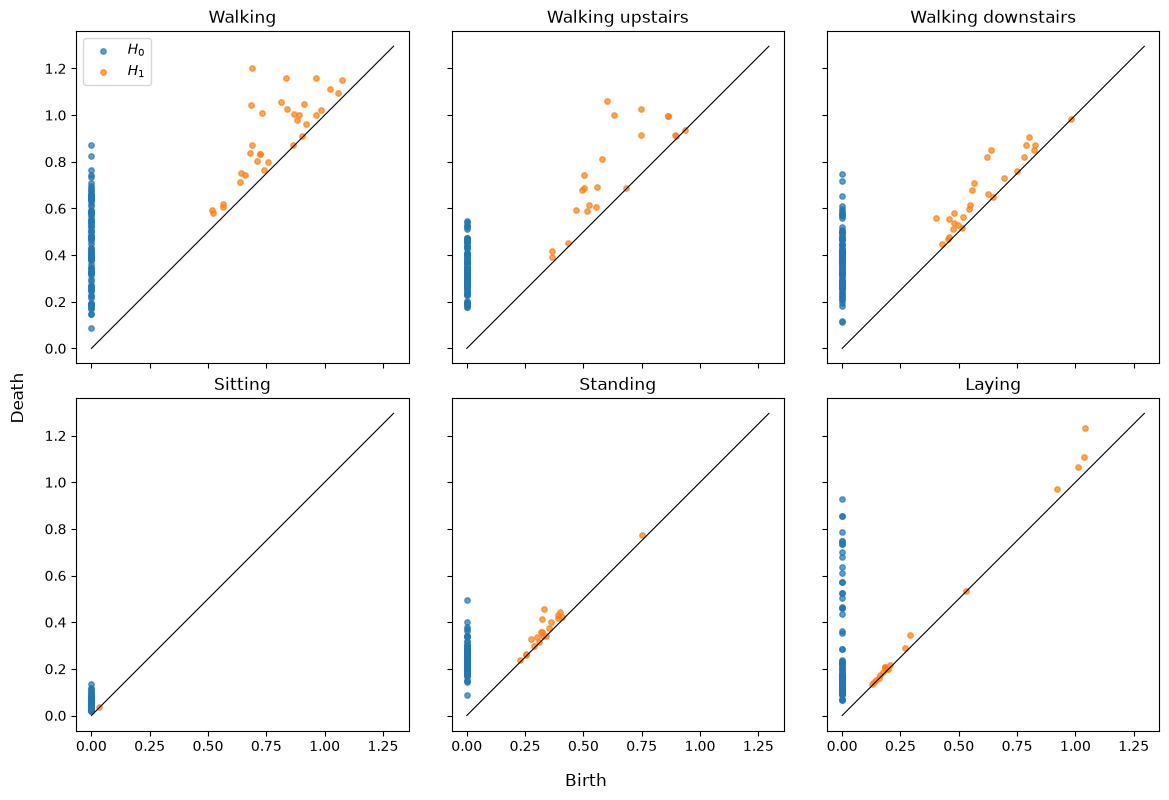

In [10]:
from plotting import plot_activity_persistence
from topology import representative_diagrams

diagrams = representative_diagrams(
    acceleration, labels, subjects, subject=1, m=m, lag=lag, normalize=True
)
plot_activity_persistence(diagrams)


Each panel shows one acceleration window for one activity from the same subject. Blue $H_0$ points describe merge scales between pieces of the cloud. Orange $H_1$ points describe loop-like structures.

The following cell makes one diagram numerical. It removes the single infinite $H_0$ class corresponding to the final connected component and sorts finite lifetimes from longest to shortest.


In [11]:
activity = int(labels[w])
h0, h1 = diagrams[activity]

finite_h0 = h0[np.isfinite(h0[:, 1])]
finite_h1 = h1[np.isfinite(h1[:, 1])]
h0_lifetimes = np.sort(finite_h0[:, 1] - finite_h0[:, 0])[::-1]
h1_lifetimes = np.sort(finite_h1[:, 1] - finite_h1[:, 0])[::-1]

print("Activity:", ACTIVITY_NAMES[activity])
print("Finite H0 classes:", len(finite_h0))
print("H1 classes:", len(finite_h1))
print("Five longest H0 lifetimes:", np.round(h0_lifetimes[:5], 4))
print("Five longest H1 lifetimes:", np.round(h1_lifetimes[:5], 4))


Activity: Standing
Finite H0 classes: 97
H1 classes: 20
Five longest H0 lifetimes: [0.4971 0.3998 0.3773 0.3714 0.3628]
Five longest H1 lifetimes: [0.1244 0.0915 0.0533 0.0432 0.0429]


### Stable ranks: from a variable barcode to a fixed vector

Different windows contain different numbers of persistence intervals, so their diagrams cannot be passed directly to an ordinary classifier. The stable-rank function summarizes a barcode $B_k=\{[b_j,d_j)\}$ by counting how many classes survive longer than a threshold $t$:

$$
S_k(t)=\#\{j:d_j-b_j>t\}.
$$

At $t=0$, $S_k(0)$ counts finite positive-lifetime classes. As $t$ increases, short classes disappear first, so $S_k(t)$ is non-increasing. Two diagrams with similar lifetime distributions have similar stable-rank curves even if their individual birth and death coordinates differ.

The function is sampled at 64 thresholds in $[0,2]$. For one window the four blocks are

$$
z_w^{\mathrm{sep}}
=
[S_0^{\mathrm{acc}}\mid S_1^{\mathrm{acc}}\mid
  S_0^{\mathrm{gyro}}\mid S_1^{\mathrm{gyro}}]
\in\mathbb{R}^{256}.
$$

The 128-dimensional joint vector instead contains $H_0$ and $H_1$ stable ranks computed after coupling the two sensors into one metric space.


### Running the complete primary experiment

The next cell is the first full-data experiment. It constructs the seven primary feature sets, performs subject-grouped model selection, and evaluates the official test subjects. `primary_analysis` caches only expensive numerical products; the notebook visibly owns the call and receives both the results and the feature matrices used below.


In [12]:
from experiments import primary_analysis

primary, primary_features = primary_analysis(
    train_sensors, labels, subjects,
    test_sensors, test_labels, test_subjects,
    recompute=RECOMPUTE,
)
separate_features = primary_features["delay_train"]

stable_rank_grid = np.asarray(primary["configuration"]["stable_rank_grid"])

print("Separate feature matrix:", separate_features.shape)
print("Stable-rank thresholds:", len(stable_rank_grid))


Separate feature matrix: (7352, 256)
Stable-rank thresholds: 64


The primary feature width follows directly from the construction: four separate blocks times 64 thresholds gives 256 coordinates.

Because every stable rank counts intervals longer than the current threshold, each 64-coordinate block should be non-increasing. This is a structural property of the mathematical definition, not a learned pattern.


In [13]:
width = len(stable_rank_grid)
blocks = [
    separate_features[:, start : start + width]
    for start in range(0, separate_features.shape[1], width)
]

print("Every stable-rank block is non-increasing:",
      all(np.all(np.diff(block, axis=1) <= 1e-12) for block in blocks))
print("Feature order: acceleration H0, acceleration H1, gyroscope H0, gyroscope H1")


Every stable-rank block is non-increasing: True
Feature order: acceleration H0, acceleration H1, gyroscope H0, gyroscope H1


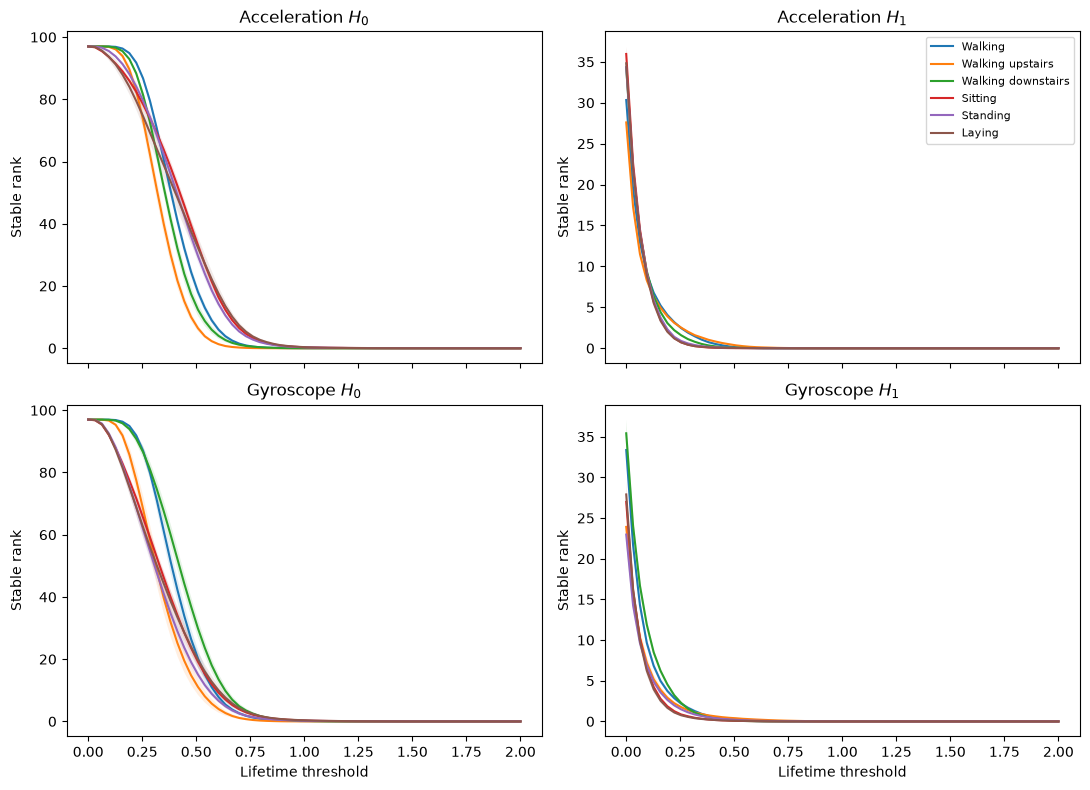

In [14]:
from plotting import plot_stable_rank_means

plot_stable_rank_means(
    separate_features, labels, subjects, stable_rank_grid
)


These plots average within each subject first and then across subjects. The curves therefore represent activity differences that are not dominated by people who happen to contribute more windows.

How to read them:

- a high $H_0$ curve means that many connected components remain separate beyond that distance scale;
- a high $H_1$ curve means that many loops persist beyond that lifetime threshold;
- separation between activity curves identifies scales where their reconstructed motion geometry differs;
- overlapping means do not imply identical individual diagrams, only similar average lifetime counts.

The curves already show that topology contains activity information. Classification asks whether the information is strong and consistent enough to predict an unseen subject.


## 4. From topological vectors to subject-independent prediction

Every representation is evaluated with the same radial-basis SVM procedure. The important part is the nesting:

1. The 21 development subjects are divided into five outer subject groups.
2. For each outer fold, four inner subject-grouped folds choose $C$ and $\gamma$ without seeing the outer subjects.
3. The selected model predicts the held-out outer subjects.
4. A final grouped search on all 21 development subjects chooses the model fitted before predicting the nine official test subjects.

No subject appears in both fitting and validation within a fold. Balanced accuracy is used because the activity counts are unequal:

$$
\operatorname{BA}
=\frac{1}{6}\sum_{c=1}^{6}
\frac{\text{correct predictions in class }c}
     {\text{windows in class }c}.
$$

Thus each activity contributes equally even when its number of windows differs.


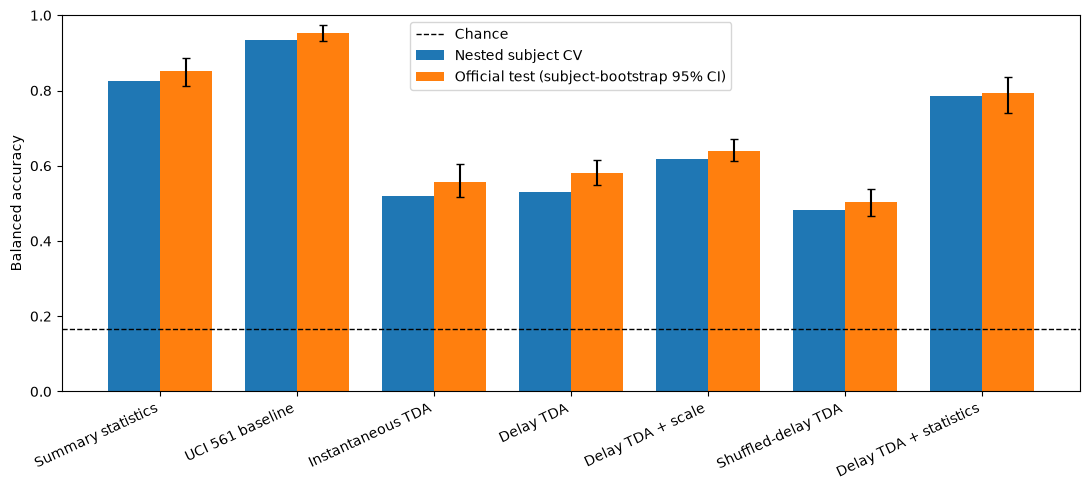

Representation                  CV BA  Test BA  Test macro-F1
----------------------------------------------------------------
Summary statistics              0.824    0.852          0.852
UCI 561 baseline                0.935    0.954          0.955
Instantaneous TDA               0.520    0.558          0.553
Delay TDA                       0.529    0.580          0.576
Delay TDA + scale               0.618    0.640          0.640
Shuffled-delay TDA              0.481    0.503          0.486
Delay TDA + statistics          0.785    0.794          0.794


In [15]:
from plotting import plot_model_comparison

plot_model_comparison(primary["models"])

print(f"{'Representation':28s} {'CV BA':>8s} {'Test BA':>8s} {'Test macro-F1':>14s}")
print("-" * 64)
for name, result in primary["models"].items():
    cv = result["grouped_cv"]["balanced_accuracy"]
    test = result["official_test"]["balanced_accuracy"]
    macro_f1 = result["official_test"]["macro_f1"]
    print(f"{name:28s} {cv:8.3f} {test:8.3f} {macro_f1:14.3f}")


### What the primary comparison says

The representations answer different questions.

- **Instantaneous TDA** uses unordered triaxial samples. It can represent the shape of the value cloud but not temporal adjacency.
- **Delay TDA** uses short histories and reaches 0.580 official-test balanced accuracy.
- **Shuffled-delay TDA** destroys temporal order before constructing delay vectors and falls to 0.503. This isolates information created by correct local ordering.
- **Delay TDA + scale** restores the two RMS radii removed during normalization and rises to 0.640. Amplitude therefore carries substantial activity information that normalized topology intentionally discarded.
- **Summary statistics** reach 0.852, and the supplied UCI feature set reaches 0.954. The topological method is not competitive as a classifier.

The scientifically useful claim is not “TDA beats ordinary features.” It is that the delay-cloud construction extracts a transferable, time-order-dependent description of motion geometry.


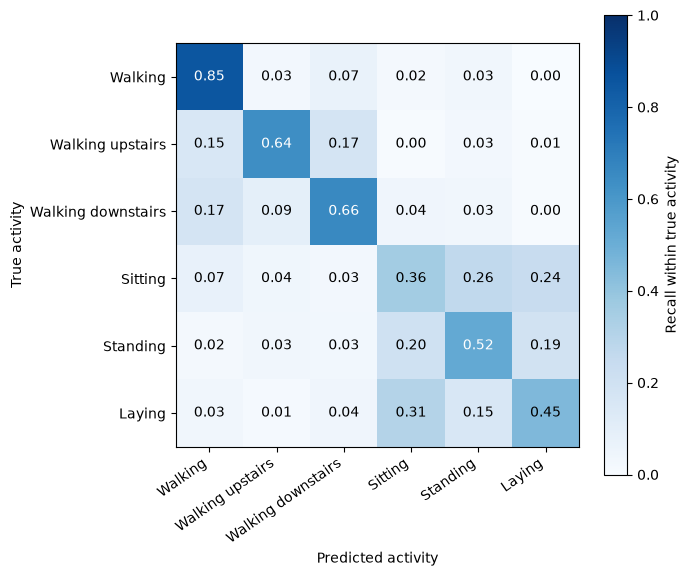

In [16]:
from plotting import plot_confusion_matrix

tda_confusion = np.asarray(
    primary["models"]["Delay TDA"]["test_confusion_matrix"]
)
plot_confusion_matrix(tda_confusion)


Rows are true activities and columns are predicted activities. Each row sums to one, so a diagonal entry is the recall for that activity: the fraction of its windows classified correctly. Delay TDA recalls walking, upstairs, and downstairs at $0.853$, $0.639$, and $0.657$, but sitting, standing, and laying at only $0.358$, $0.523$, and $0.453$. The off-diagonal mass shows that the model mainly confuses the three static postures with one another. Their normalized cloud shapes are similar, and normalization removes absolute movement scale, one of the clearest differences between static and dynamic windows.


## 5. What temporal information did the topology use?

Three comparisons separate different meanings of “temporal.”

### Instantaneous versus delay topology

The instantaneous cloud contains the same 128 vectors after any permutation of time. Its pairwise-distance matrix changes only by simultaneous row and column permutation, so its Vietoris--Rips persistence is exactly invariant to sample order.

The delay cloud changes under a general shuffle because different measurements become members of the same nine-dimensional point. A performance difference therefore measures information supplied by local temporal adjacency.

### Delay versus shuffled-delay topology

Both representations have the same dimension and use the same persistence pipeline. The only change is whether the ordering used to form each delay vector is genuine. The 0.075 mean subject-level advantage for correct order has a 95% interval $[0.037,0.108]$.

### Full time reversal

Reversing a whole window reverses the three time blocks in every delay vector and relabels the 98 points. This is a coordinate permutation, so Euclidean distances and persistence remain unchanged. The representation uses adjacency but cannot identify the arrow of time.


In [17]:
from experiments import robustness_analysis

robustness = robustness_analysis(
    train_sensors, labels, subjects,
    test_labels, test_subjects,
    primary, primary_features,
    recompute=RECOMPUTE,
)

for comparison_name, result in robustness["paired_controls"].items():
    print(comparison_name.replace("_", " "))
    print("  mean subject difference:", round(result["mean"], 3))
    print("  95% interval:", [round(value, 3) for value in result["ci"]])
    print("  exact sign-flip p:", round(result["exact_two_sided_sign_flip_p"], 4))


delay minus instantaneous
  mean subject difference: 0.021
  95% interval: [-0.001, 0.043]
  exact sign-flip p: 0.125
delay minus shuffled
  mean subject difference: 0.075
  95% interval: [0.037, 0.108]
  exact sign-flip p: 0.0117


Delay topology is clearly better than the shuffled-delay control, but its smaller advantage over instantaneous topology is uncertain at the nine-subject level. The evidence therefore supports sensitivity to correct local order without establishing that every unordered topological representation is inferior.


### Geometric separation and sensitivity

Stable-rank distance approximates the $L^1$ difference between two sampled stable-rank functions. Averaging within each subject and activity produces prototypes that can be compared without allowing subjects with more windows to dominate.


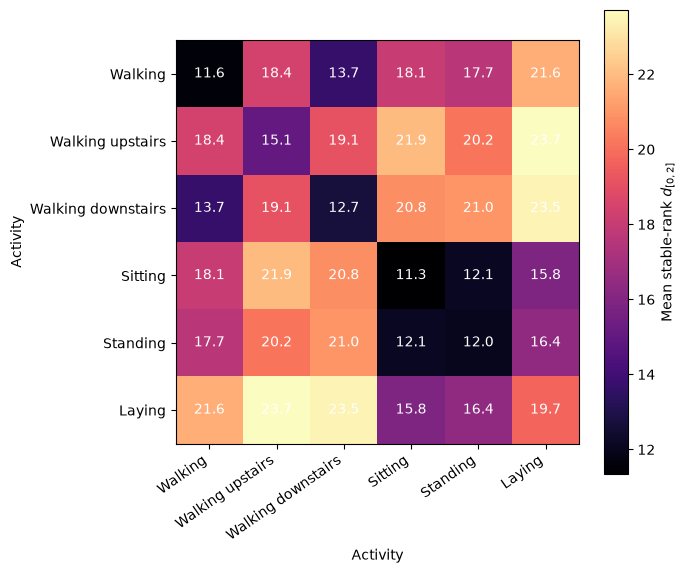

Between/within activity distance ratio: 1.377


In [18]:
from plotting import plot_activity_distance_matrix

distance_matrix = np.asarray(robustness["subject_activity_distances"])
plot_activity_distance_matrix(distance_matrix)
print("Between/within activity distance ratio:",
      round(robustness["between_within_ratio"], 3))


A ratio above one means that changing the activity alters the stable-rank representation more than changing the subject within a fixed activity, on average. This connects the geometric feature space directly to the intended invariance: activity should matter more than personal movement style.

The next figures vary $m$, $\ell$, and the point-cloud metric, then perturb the input signal with Gaussian noise. The purpose is not to find a best setting after seeing the test result. It is to see whether the qualitative conclusion depends on one narrow numerical choice.


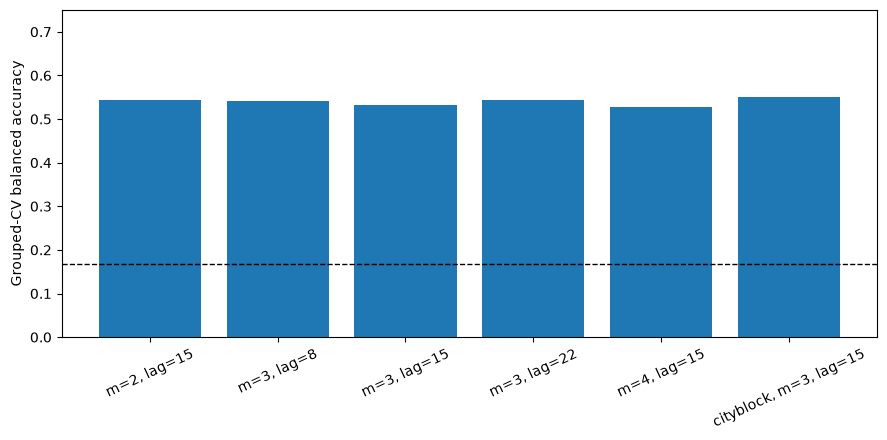

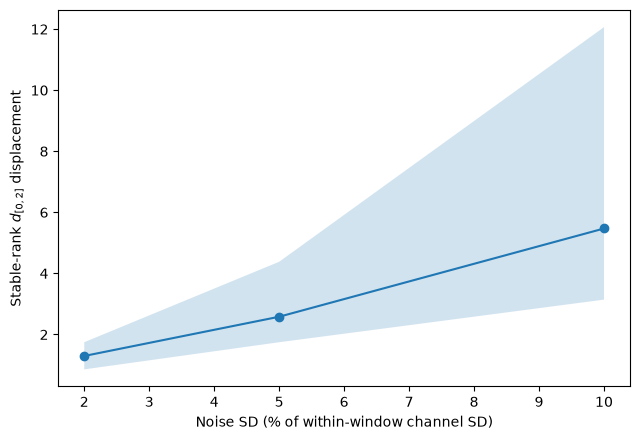

In [19]:
from plotting import plot_noise_robustness, plot_sensitivity

plot_sensitivity(robustness["sensitivity"])
plot_noise_robustness(robustness["noise"])


The nearby embedding choices give similar development performance, so $m=3$ and $\ell=15$ are not an isolated successful point. Noise changes the stable-rank vectors gradually. This is empirical robustness for this dataset; it is not by itself a proof of a persistence-stability theorem.


## 6. Coupling acceleration and gyroscope geometry

The 256-dimensional separate representation computes two independent barcodes. It knows the geometry of the acceleration cloud and the geometry of the gyroscope cloud, but it forgets which acceleration delay vector occurred at the same time as which gyroscope delay vector.

Two coupled constructions test whether cross-sensor pairing adds useful geometry.

### Euclidean joint cloud

After separately normalizing the sensor blocks, define

$$
q_i^{(\lambda)}=
\left(
\sqrt{\lambda}\,\widetilde\Phi_i^{\mathrm{acc}},
\sqrt{1-\lambda}\,\widetilde\Phi_i^{\mathrm{gyro}}
\right).
$$

Then

$$
\lVert q_i^{(\lambda)}-q_j^{(\lambda)}\rVert_2^2
=\lambda d_a(i,j)^2+(1-\lambda)d_g(i,j)^2.
$$

One sensor can compensate for the other: a pair may remain close overall when it is very close in acceleration but less close in gyroscope.

### Max-product metric

The alternative distance is

$$
d_\lambda^{\max}(i,j)
=\max\left\{
\sqrt{2\lambda}\,d_a(i,j),
\sqrt{2(1-\lambda)}\,d_g(i,j)
\right\}.
$$

At equal weights,

$$
d_{1/2}^{\max}(i,j)\leq\varepsilon
\quad\Longleftrightarrow\quad
d_a(i,j)\leq\varepsilon
\text{ and }
d_g(i,j)\leq\varepsilon.
$$

An edge therefore appears only when both sensor histories are close. This is a one-parameter slice through the two-threshold product filtration.


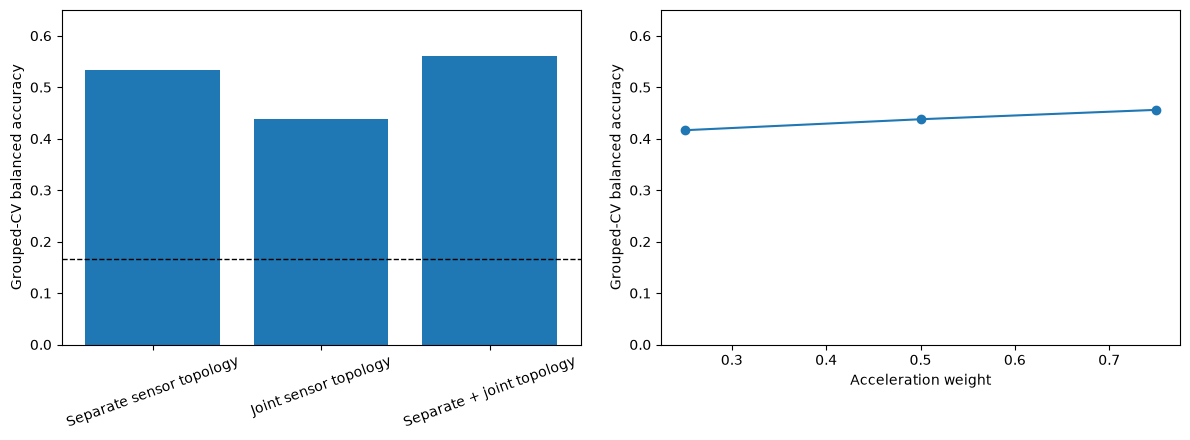

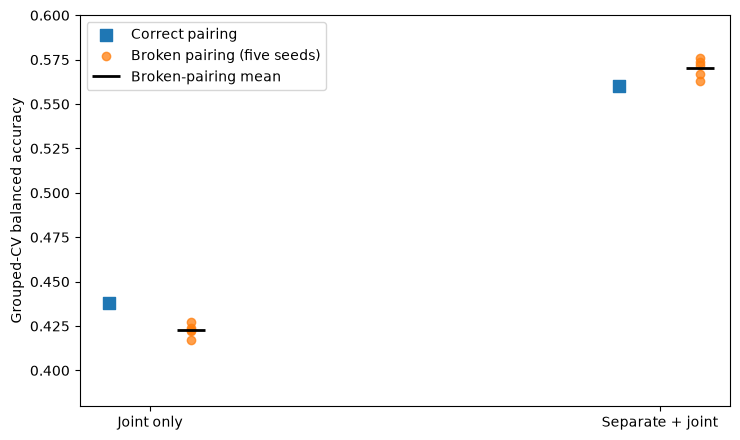

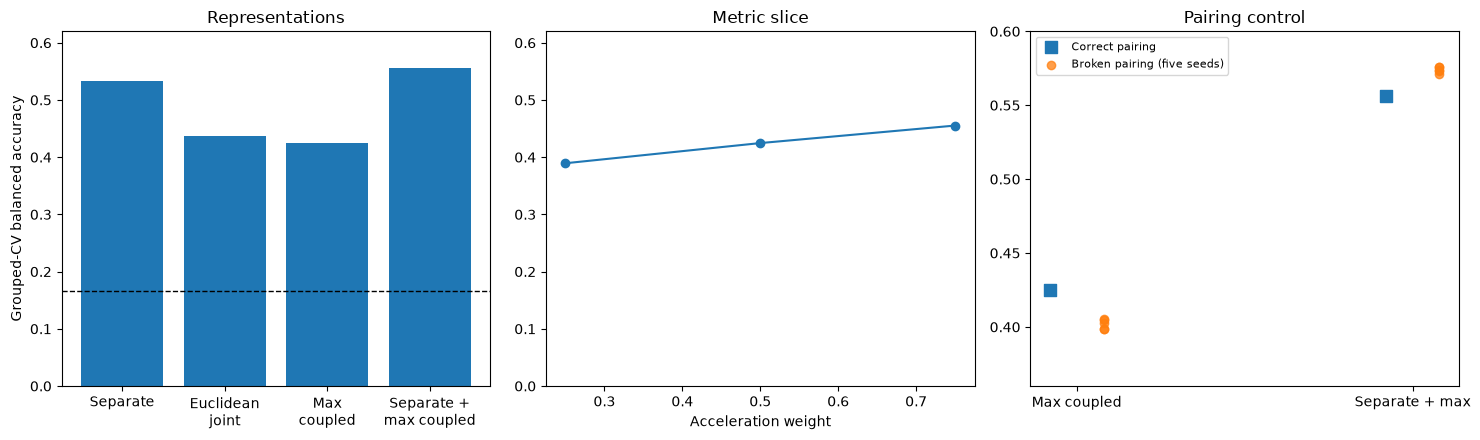

In [20]:
from experiments import extension_analysis
from plotting import (
    plot_coupled_max_analysis,
    plot_joint_analysis,
    plot_synchronization_control,
)

extensions = extension_analysis(
    train_sensors, labels, subjects,
    test_labels, test_subjects,
    primary, primary_features,
    recompute=RECOMPUTE,
)

plot_joint_analysis(extensions["joint_representation"])
plot_synchronization_control(extensions["joint_representation"])
plot_coupled_max_analysis(extensions["coupled_max_representation"])


On the 21 development subjects, separate topology scores 0.533. Euclidean-joint topology scores 0.438 alone and 0.560 when appended to the separate features. Max-coupled topology scores 0.425 alone and 0.557 when appended.

The concatenated vectors therefore contain complementary coordinates. That alone does not show that correct sensor synchronization caused the improvement.

To isolate synchronization, the gyroscope delay points are deranged within each window:

$$
q_i^{\mathrm{broken}}
=\left(
\sqrt{\lambda}\,\widetilde\Phi_i^{\mathrm{acc}},
\sqrt{1-\lambda}\,\widetilde\Phi_{\pi(i)}^{\mathrm{gyro}}
\right).
$$

This leaves both marginal clouds and both separate persistence diagrams exactly unchanged. It changes only which gyroscope history is paired with each acceleration history.

Broken pairing performs at least as well once its features are appended to separate topology. The supported conclusion is therefore narrow: coupled metrics create complementary transformations, but these experiments do not attribute the gain to correct acceleration--gyroscope synchronization.


## 7. Which sensor and homology degree contribute?

The 256 stable-rank coordinates naturally split into four blocks. Training the same grouped classifier on individual blocks asks whether the result is carried by one sensor or one homological degree.


In [21]:
{
    name: round(value["balanced_accuracy"], 3)
    for name, value in extensions["ablations"].items()
}


{'Acceleration H0': 0.36,
 'Acceleration H1': 0.337,
 'Gyroscope H0': 0.309,
 'Gyroscope H1': 0.346,
 'Both sensors H0': 0.442,
 'Both sensors H1': 0.451,
 'Acceleration H0+H1': 0.47,
 'Gyroscope H0+H1': 0.374,
 'All H0+H1': 0.533}

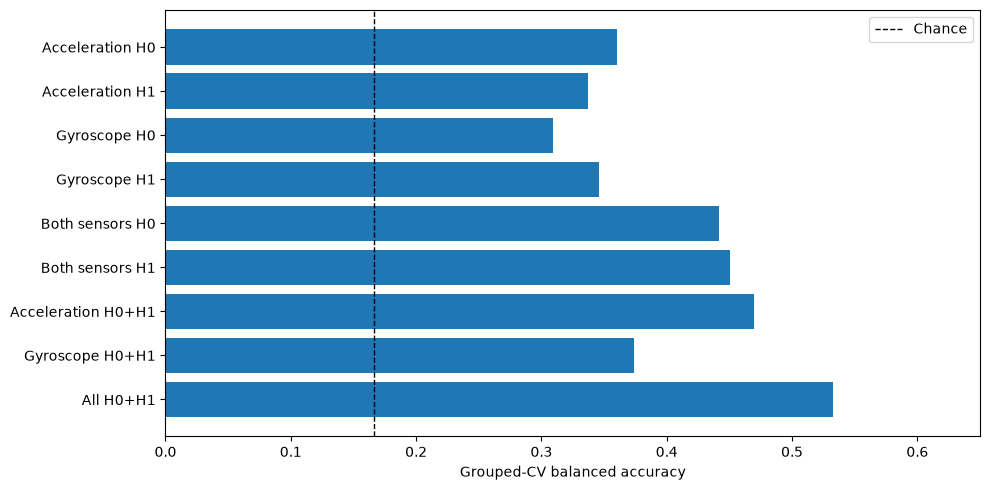

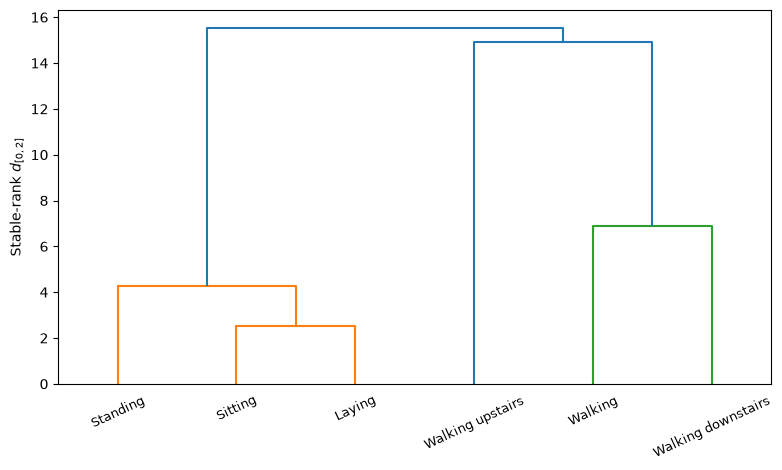

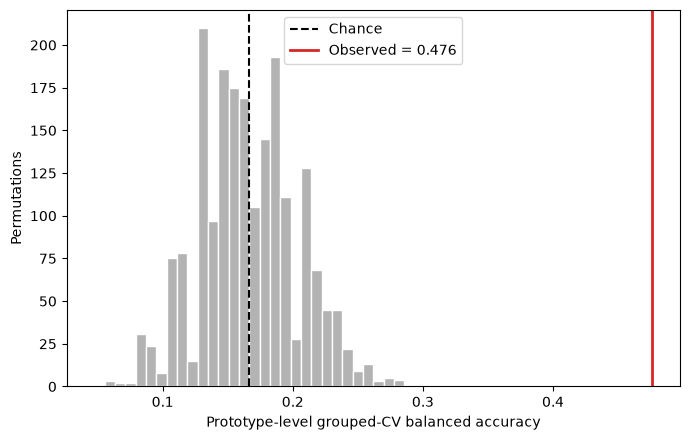

In [22]:
from plotting import (
    plot_activity_dendrogram,
    plot_permutation_null,
    plot_topology_ablation,
)

plot_topology_ablation(extensions["ablations"])
plot_activity_dendrogram(
    np.asarray(extensions["prototype_activity_distance_matrix"])
)
plot_permutation_null(extensions["prototype_permutation_test"])


Acceleration alone scores 0.470 and gyroscope alone 0.374. Using both sensors, $H_0$ alone scores 0.442 and $H_1$ alone 0.451. The full four-block vector reaches 0.533 on grouped development folds. No single block explains the complete result.

The dendrogram is built from subject-balanced activity prototypes rather than classifier predictions. It separates static from moving activities, showing that the stable-rank geometry contains an unsupervised activity organization.

The nearest-prototype score is 0.476, compared with a mean of 0.168 after labels are permuted independently within subjects. This asks a geometric question: are same-activity prototypes closer than expected if activity names carried no relation to the feature space?


## 8. Persistent loops as circular motion coordinates

Stable ranks retain lifetime counts but discard the identity of individual cocycles and the position of each delay point around a loop. The circular-coordinate branch asks whether the most persistent $H_1$ class can provide an interpretable phase variable.

Ripser returns a representative $H^1$ cocycle $\alpha$ corresponding to the longest $H_1$ interval. At the midpoint of that interval, its coefficients over $\mathbb F_{47}$ are lifted to integers and smoothed by solving

$$
\widehat f
=\operatorname*{arg\,min}_f
\lVert\alpha+\delta f\rVert_2^2.
$$

Here $\delta f$ is the difference of the vertex potential $f$ across each edge present at that filtration scale. Reducing the fitted potential modulo one gives a circle-valued coordinate

$$
\theta_i=\widehat f_i\bmod 1.
$$

The delay points retain their original time indices. After converting $\theta_i$ to an angle and unwrapping it, a linear fit through time produces two features:

- **circular frequency:** the magnitude of fitted phase slope divided by $2\pi$;
- **circular linearity:** the $R^2$ of that linear fit.

A high linearity means the window moves around the recovered topological circle at an approximately steady phase rate. A low value means that a loop may exist geometrically without providing a coherent temporal phase.

For each sensor the representation also records $H_0$ merge scales, the number and total persistence of $H_1$ classes, and the birth and lifetime of the longest loop. The same construction is applied to every window from all six activities. The two sensors together produce 16 interpretable features.


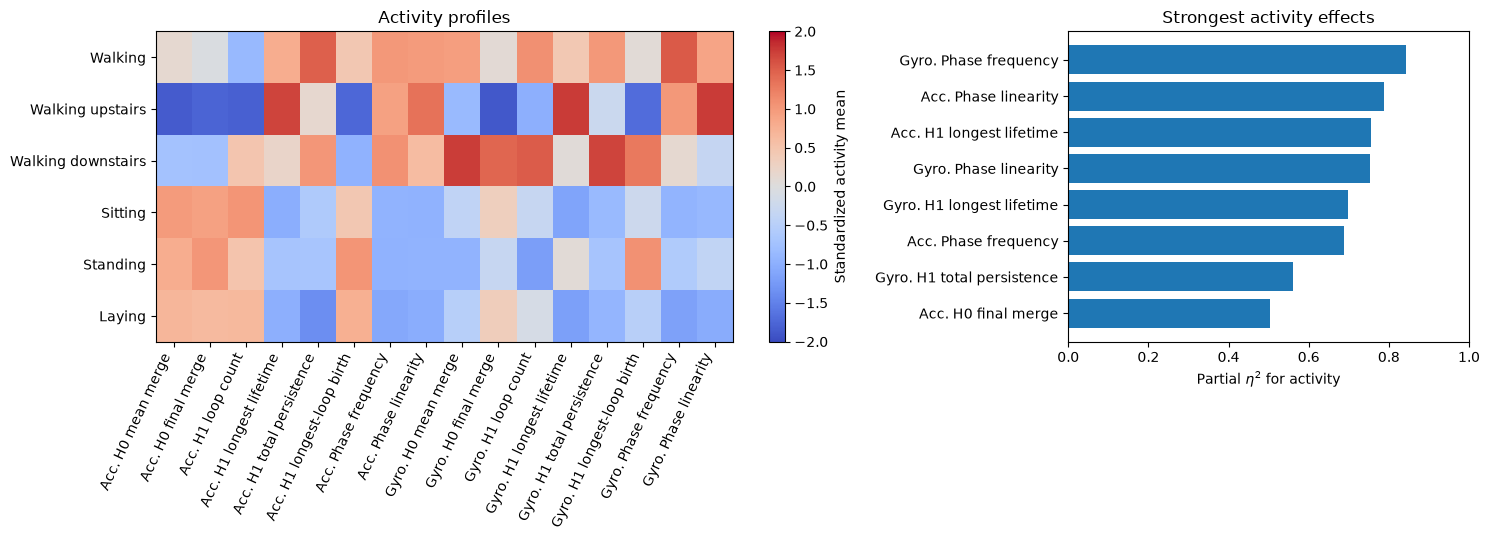

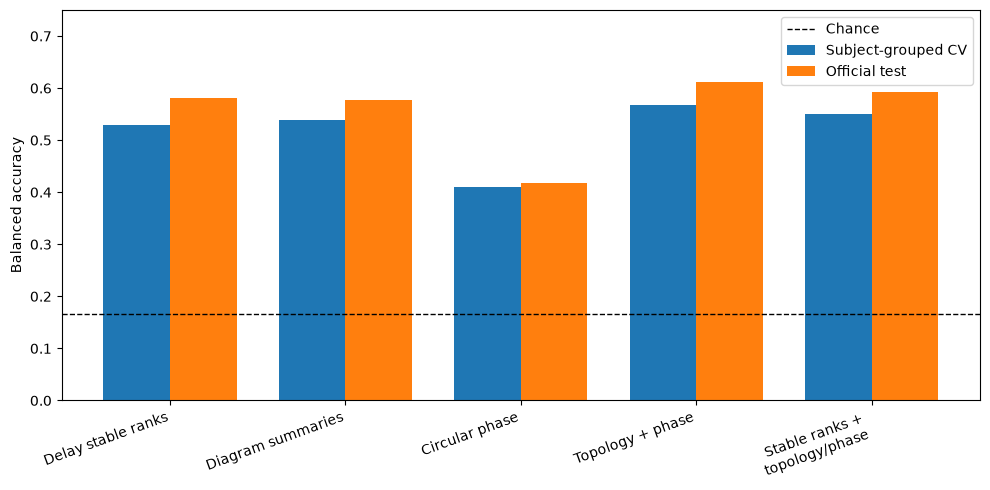

Representation                              CV BA  Test BA
------------------------------------------------------------
Diagram summaries                           0.539    0.577
Circular phase                              0.410    0.418
Topological dynamics                        0.567    0.611
Delay TDA + topological dynamics            0.550    0.593


In [23]:
from experiments import dynamics_analysis
from plotting import plot_dynamics_classification, plot_topological_dynamics

dynamics, dynamics_features = dynamics_analysis(
    train_sensors, labels, subjects,
    test_sensors, test_labels, test_subjects,
    primary, primary_features,
    recompute=RECOMPUTE,
)

plot_topological_dynamics(dynamics)
plot_dynamics_classification(primary, dynamics)

print(f"{'Representation':40s} {'CV BA':>8s} {'Test BA':>8s}")
print("-" * 60)
for name, result in dynamics["models"].items():
    cv = result["grouped_cv"]["balanced_accuracy"]
    test = result["official_test"]["balanced_accuracy"]
    print(f"{name:40s} {cv:8.3f} {test:8.3f}")


In the activity-profile heatmap, rows are activities and columns are the 16 features. Color shows each activity mean after standardizing within a feature, so red means high relative to the other activities, not a larger value in shared physical units. The adjacent bars show partial $\eta_p^2$: the fraction of remaining feature variation associated with activity after subject means are removed.

Gyroscope circular frequency has the largest activity effect ($\eta_p^2=0.844$), followed by acceleration phase linearity ($0.787$) and acceleration longest-loop lifetime ($0.754$).

For dynamic activities, circular frequency is positively associated with ordinary Fourier frequency ($\rho=0.362$ for acceleration and $0.271$ for gyroscope). The values are not identical because one measures rotation around a reconstructed topological loop while the other measures spectral power in the original signal.

Diagram summaries alone score 0.577 and the four circular-phase features alone score 0.418 on the official test. Their 16-feature union reaches 0.611, compared with 0.580 for the 256 stable-rank coordinates. Appending all stable-rank coordinates lowers the score to 0.593.

The compact topology-and-phase vector is therefore the strongest tested topology-only representation. It succeeds not by retaining more coordinates, but by exposing a few geometrically meaningful quantities directly.


## 9. What the complete analysis establishes

| Question | Evidence | Supported conclusion |
|---|---|---|
| Does topology contain activity information? | Subject-grouped prediction, prototype distances, clustering | Yes. Stable-rank geometry transfers across subjects and organizes activities non-randomly. |
| Does local time order matter? | Delay versus shuffled-delay topology | Yes. Correct temporal adjacency improves the representation. |
| Does the method recover time direction? | Exact full-reversal invariance | No. Euclidean delay persistence cannot distinguish forward from reversed windows. |
| Is normalized topology the strongest classifier? | Scale restoration and ordinary baselines | No. Removing amplitude costs information, and ordinary signal features are much stronger. |
| Do coupled metrics add coordinates? | Separate versus separate-plus-coupled features | Yes, on development subjects. |
| Is the coupled gain caused by correct synchronization? | Marginal-preserving gyroscope derangement | Not established. Broken pairing performs at least as well after concatenation. |
| Can persistent loops yield interpretable dynamics? | Circular frequency, phase linearity, and spectral comparison | Yes, especially for dynamic activities, although phase features alone are insufficient for classification. |

The project therefore demonstrates a complete TDA pipeline rather than a leaderboard result. Delay coordinates convert short movement histories into finite metric spaces; persistent homology describes their multiscale connectivity and loops; stable ranks and circular coordinates turn those structures into comparable features; and the experiments determine precisely which aspects of activity those features retain.
